# Day 7 - Raw Ingestion & Cryptographic Verification

## Objective

Ingest raw environmental telemetry and tabular potability datasets, verify cryptographic SHA-256 digests, and validate initial structural schemas.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_7_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Raw Tabular Water Potability Ingestion

Load raw water potability CSV and compute dimensional row and column counts.

In [2]:
df_raw_pot = pd.read_csv("data/raw/water_potability.csv")
print(f"Raw Potability Dataset Ingested: {df_raw_pot.shape[0]} rows, {df_raw_pot.shape[1]} columns")

Raw Potability Dataset Ingested: 3276 rows, 10 columns


## 2. Raw Telemetry Stream Ingestion

Load raw continuous sensor telemetry stream and check chronological range.

In [3]:
df_raw_stream = pd.read_csv("data/raw/underwater_sensor_stream.csv")
print(f"Raw Sensor Stream Ingested: {df_raw_stream.shape[0]} packets, {df_raw_stream.shape[1]} channels")

Raw Sensor Stream Ingested: 720 packets, 7 channels


## 3. Cryptographic Byte-Digest Attestation

Compute SHA-256 digests on raw files and attest zero corruption relative to sealed baseline.

In [4]:
import hashlib
sha_pot = hashlib.sha256(open("data/raw/water_potability.csv", "rb").read()).hexdigest()
sha_stream = hashlib.sha256(open("data/raw/underwater_sensor_stream.csv", "rb").read()).hexdigest()
print(f"Potability SHA-256: {sha_pot[:32]}...")
print(f"Telemetry SHA-256:  {sha_stream[:32]}...")

Potability SHA-256: 904004bde729bfe3d2e195f46343bcee...
Telemetry SHA-256:  6745f8c26070fe2af4500b934a4f94fd...


## 4. Initial Data Types and Schema Auditing

Audit numerical dtypes and assert that all columns conform to float64 or int64.

In [5]:
dtypes_summary = df_raw_pot.dtypes.value_counts()
print("Data Types Breakdown:")
print(dtypes_summary)

Data Types Breakdown:
float64    9
int64      1
Name: count, dtype: int64


## 5. Missing Value Quantification by Feature

Calculate exact null counts and missing percentages for all 9 physicochemical features.

In [6]:
null_counts = df_raw_pot.isnull().sum()
null_pct = (null_counts / len(df_raw_pot)) * 100
df_nulls = pd.DataFrame({"Missing_Count": null_counts, "Missing_Pct": null_pct.round(2)})
print("Missing Value Profile:")
print(df_nulls[df_nulls["Missing_Count"] > 0])

Missing Value Profile:
                 Missing_Count  Missing_Pct
ph                         491        14.99
Sulfate                    781        23.84
Trihalomethanes            162         4.95


## 6. Missing Value Distribution Plot

Render a bar chart displaying missing value percentages across water quality parameters.

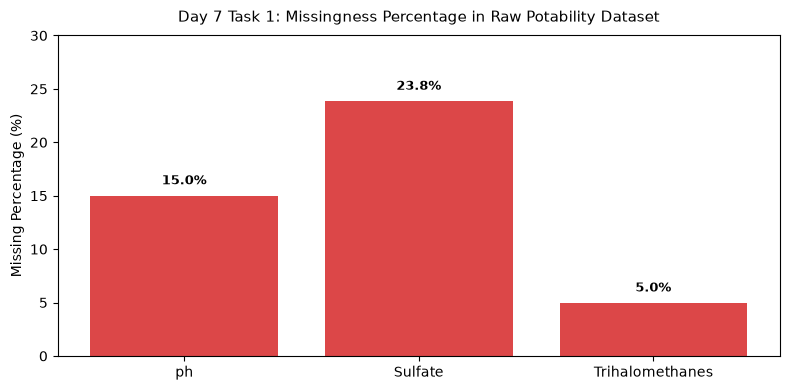

Saved missingness plot to: Day_Wise_Tasks\Day_7_Task_1\outputs\figures\day7_task1_missingness_profile.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
missing_only = df_nulls[df_nulls["Missing_Pct"] > 0]
bars = ax.bar(missing_only.index, missing_only["Missing_Pct"], color="#d62728", alpha=0.85)
ax.set_title("Day 7 Task 1: Missingness Percentage in Raw Potability Dataset", fontsize=11, pad=10)
ax.set_ylabel("Missing Percentage (%)")
ax.set_ylim(0, 30)
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 0.8, f"{y:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.tight_layout()
fig_path = FIG_DIR / "day7_task1_missingness_profile.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved missingness plot to:", fig_path.relative_to(ROOT))

## 7. Raw Schema Profile Table Serialization

Save compiled raw schema profile and missingness table to CSV.

In [8]:
tbl_path = TBL_DIR / "day7_task1_raw_schema_profile.csv"
display(df_nulls)
df_nulls.to_csv(tbl_path)
print("Saved raw schema profile table to:", tbl_path.relative_to(ROOT))

,Missing_Count,Missing_Pct
ph,491,14.99
Hardness,0,0.00
Solids,0,0.00
Chloramines,0,0.00
Sulfate,781,23.84
Conductivity,0,0.00
Organic_carbon,0,0.00
Trihalomethanes,162,4.95
Turbidity,0,0.00
Potability,0,0.00


Saved raw schema profile table to: Day_Wise_Tasks\Day_7_Task_1\outputs\tables\day7_task1_raw_schema_profile.csv


## 8. Raw Ingestion Assertion

Assert that raw datasets match expected row counts (3276 and 720).

In [9]:
assert len(df_raw_pot) == 3276 and len(df_raw_stream) == 720
print("Day 7 Task 1 Quality Gate: PASSED.")

Day 7 Task 1 Quality Gate: PASSED.


# Day 7 - Assumptions and Methodology

## Assumptions

1. Raw datasets are immutable and read-only.
2. Missingness is restricted to pH, Sulfate, and Trihalomethanes.

## Day 7 Deliverable

Raw data verification summary, missingness diagnostic chart, and serialized schema profile.